# Uniform Cost Search: Nairobi to Kisumu

**Initial state:** Nairobi. **Goal state:** Kisumu. **Path cost:** cumulative directed-edge distance in kilometres.

Distances used by the program follow the Part 1 calculations in [design.md](https://github.com/NJ-IVE/PS-agents/blob/main/design.md).

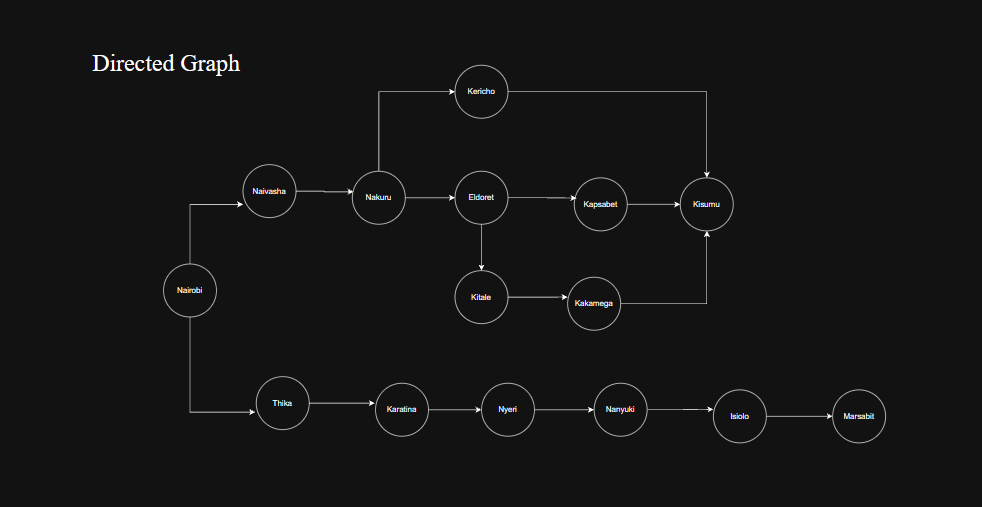


Importation for count and heap

In [1]:
import heapq
from itertools import count

The list of places and distances from them to other places.

In [2]:
graph = {
    "Nairobi": [("Naivasha", 91.0), ("Thika", 45.1)],
    "Naivasha": [("Nakuru", 71.1)],
    "Nakuru": [("Kericho", 107), ("Eldoret", 156)],
    "Kericho": [("Kisumu", 84)],
    "Eldoret": [("Kapsabet", 46), ("Kitale", 74.9)],
    "Kapsabet": [("Kisumu", 80.3)],
    "Kitale": [("Kakamega", 110)],
    "Kakamega": [("Kisumu", 53.4)],
    "Thika": [("Karatina", 88.4)],
    "Karatina": [("Nyeri", 24.7)],
    "Nyeri": [("Nanyuki", 61)],
    "Nanyuki": [("Isiolo", 79.5)],
    "Isiolo": [("Marsabit", 257)],
    "Kisumu": [],
    "Marsabit": []
}


Places to be visited, arranging the places when distances are equal.Remember the route with the best cost to each place, the starting place and the places already visited.

Pick the place with the lowest distance and skip an already visited place.Check arrival to the destination. This also checks the neighbouring places to the current place

In [3]:
def searching_with_uniform_cost_search(graph, start_node, end_node):

    waiting_list = []
    arrangement = count()

    heapq.heappush(waiting_list, (0, next(arrangement), start_node))

    best_cost = {start_node: 0}
    where_came_from = {start_node: None}
    places_visited = set()
    step = 1

    while waiting_list:

        cost, _, current = heapq.heappop(waiting_list)

        if cost != best_cost[current]:
            continue

        if current in places_visited:
            continue

        places_visited.add(current)

        print("\nStep", step)
        print("Exploring:", current)
        print("Total cost:", round(cost, 2), "km")

        step += 1

        if current == end_node:

            print("Goal reached!")

            path = []
            place = end_node

            while place is not None:
                path.append(place)
                place = where_came_from[place]

            path.reverse()

            print("Shortest path:", " -> ".join(path))
            print("Total distance:", round(cost, 2), "km")

            return path, cost

        for neighbor, distance in graph[current]:

            new_cost = cost + distance

            if (neighbor not in places_visited and
                (neighbor not in best_cost or
                 new_cost < best_cost[neighbor])):

                best_cost[neighbor] = new_cost

                where_came_from[neighbor] = current

                heapq.heappush(
                    waiting_list,
                    (new_cost, next(arrangement), neighbor)
                )

                print("  Added:", neighbor,
                      "| Total cost:", round(new_cost, 2), "km")

    print("\nNo route found!")
    return None, float("inf")

Ask for the place and destination then collect all the places in the graph to check if they exist.

In [4]:
start_node = input("Enter the starting place: ").strip().title()
end_node = input("Enter the destination place: ").strip().title()


# Collect all the cities in the graph
all_places = set(graph.keys())

for associations in graph.values():
    for neighbor, distance in associations:
        all_places.add(neighbor)


# Check whether the entered cities exist
if start_node not in all_places or end_node not in all_places:
    print("Invalid name of a place")

else:
    searching_with_uniform_cost_search(graph, start_node, end_node)

Enter the starting place: Nairobi
Enter the destination place: Kisumu

Step 1
Exploring: Nairobi
Total cost: 0 km
  Added: Naivasha | Total cost: 91.0 km
  Added: Thika | Total cost: 45.1 km

Step 2
Exploring: Thika
Total cost: 45.1 km
  Added: Karatina | Total cost: 133.5 km

Step 3
Exploring: Naivasha
Total cost: 91.0 km
  Added: Nakuru | Total cost: 162.1 km

Step 4
Exploring: Karatina
Total cost: 133.5 km
  Added: Nyeri | Total cost: 158.2 km

Step 5
Exploring: Nyeri
Total cost: 158.2 km
  Added: Nanyuki | Total cost: 219.2 km

Step 6
Exploring: Nakuru
Total cost: 162.1 km
  Added: Kericho | Total cost: 269.1 km
  Added: Eldoret | Total cost: 318.1 km

Step 7
Exploring: Nanyuki
Total cost: 219.2 km
  Added: Isiolo | Total cost: 298.7 km

Step 8
Exploring: Kericho
Total cost: 269.1 km
  Added: Kisumu | Total cost: 353.1 km

Step 9
Exploring: Isiolo
Total cost: 298.7 km
  Added: Marsabit | Total cost: 555.7 km

Step 10
Exploring: Eldoret
Total cost: 318.1 km
  Added: Kapsabet | Total